# 01 - Data Generation & EDA

**Project:** Visual trademark logo similarity search

## Business problem
Before filing a new trademark, an IP consultant has to check whether a client's logo is
confusingly similar to marks that are already registered or published. Doing this by eye
against thousands of logos is slow and inconsistent. Infringing or "look-alike" marks are
rarely exact copies: the colour changes, a letter changes, the shape is altered slightly,
or the image is a low-quality scan.

**Goal:** given a query logo, return the most visually similar logos from a database,
with a similarity score and a risk level, so a consultant only has to review a short list.

## Why synthetic data?
* **Ground truth.** Every variant is generated from a known parent logo, so we know
  exactly which logos are "the same mark". Real logo datasets rarely have this label.
* **No IP issues.** No third-party logos are published in this repository.
* **Controlled difficulty.** Each variant records which modifications were applied,
  so we can measure which kinds of changes the model handles well or badly.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

DATA_DIR = ROOT / "data" / "dummy_logos"
IMAGE_DIR = DATA_DIR / "images"
ASSETS = ROOT / "assets"
RESULTS = ROOT / "results"
MODELS = ROOT / "models"
for d in (ASSETS, RESULTS, MODELS):
    d.mkdir(exist_ok=True)
SEED = 42

import subprocess
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from viz import show_families

## 1. Generate the dataset
1,000 parent logos x (1 parent + 8 variants) = **9,000 images**.
Skipped automatically if the dataset already exists.

In [2]:
N_PARENTS, N_VARIANTS = 1000, 8

if not (DATA_DIR / "metadata.csv").exists():
    result = subprocess.run(
        [sys.executable, str(ROOT / "src" / "generate_logos.py"),
         "--n-parents", str(N_PARENTS), "--n-variants", str(N_VARIANTS),
         "--seed", str(SEED), "--out", str(DATA_DIR)],
        check=True, capture_output=True, text=True)
    print(result.stdout[-400:])
else:
    print("Dataset already exists:", DATA_DIR)

shutil.copy(DATA_DIR / "preview.png", ASSETS / "preview.png")

/1000 logo induk selesai
  700/1000 logo induk selesai
  800/1000 logo induk selesai
  900/1000 logo induk selesai
  1000/1000 logo induk selesai

Selesai: 9000 gambar di c:\Users\yunido\trademark-logo-similarity\data\dummy_logos\images
Metadata: c:\Users\yunido\trademark-logo-similarity\data\dummy_logos\metadata.csv
Preview : c:\Users\yunido\trademark-logo-similarity\data\dummy_logos\preview.png



WindowsPath('c:/Users/yunido/trademark-logo-similarity/assets/preview.png')

## 2. Metadata overview

In [3]:
df = pd.read_csv(DATA_DIR / "metadata.csv")
print(df.shape)
df.head(10)

(9000, 9)


,filename,parent_id,is_parent,variant_types,brand_text,initials,shape,layout,split
0,p0001_v00.png,1,1,NaN,Goanto Mart,GM,triangle,badge,val
1,p0001_v01.png,1,0,layout_shift,Goanto Mart,GM,triangle,badge,val
2,p0001_v02.png,1,0,grayscale+layout_shift,Goanto Mart,GM,triangle,badge,val
3,p0001_v03.png,1,0,layout_shift+crop_zoom,Goanto Mart,GM,triangle,badge,val
4,p0001_v04.png,1,0,color_shift+text_typo,Goamto Mart,GM,triangle,badge,val
5,p0001_v05.png,1,0,crop_zoom+scan_noise,Goanto Mart,GM,triangle,badge,val
6,p0001_v06.png,1,0,rotate+flip,Goanto Mart,GM,triangle,badge,val
7,p0001_v07.png,1,0,rotate,Goanto Mart,GM,triangle,badge,val
8,p0001_v08.png,1,0,flip+crop_zoom,Goanto Mart,GM,triangle,badge,val
9,p0002_v00.png,2,1,NaN,Losaga Food,LF,circle,inline,train


In [4]:
split_summary = df.groupby("split").agg(images=("filename", "count"),
                                        parent_logos=("parent_id", "nunique"))
split_summary.loc["total"] = split_summary.sum()
split_summary

,images,parent_logos
split,,
test,1350,150
train,6300,700
val,1350,150
total,9000,1000


The split is done **per parent logo**: all variants of one logo are in the same split.
This prevents leakage: the model is always evaluated on marks it has never seen during training.

In [5]:
assert df.groupby("parent_id")["split"].nunique().max() == 1, "leakage between splits!"
print("No parent logo appears in more than one split.")

No parent logo appears in more than one split.


## 3. Parent logo attributes

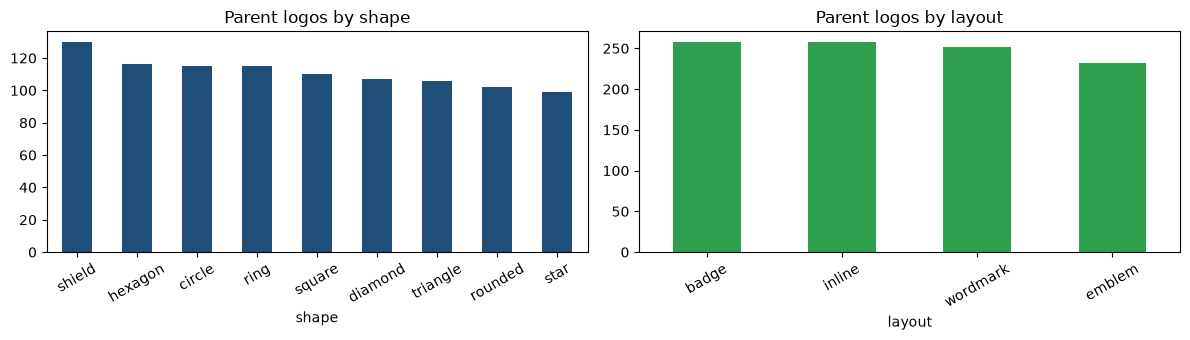

In [6]:
parents = df[df.is_parent == 1]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
parents["shape"].value_counts().plot.bar(ax=axes[0], color="#1f4e79")
axes[0].set_title("Parent logos by shape")
parents["layout"].value_counts().plot.bar(ax=axes[1], color="#2e9e4f")
axes[1].set_title("Parent logos by layout")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## 4. Variant modifications

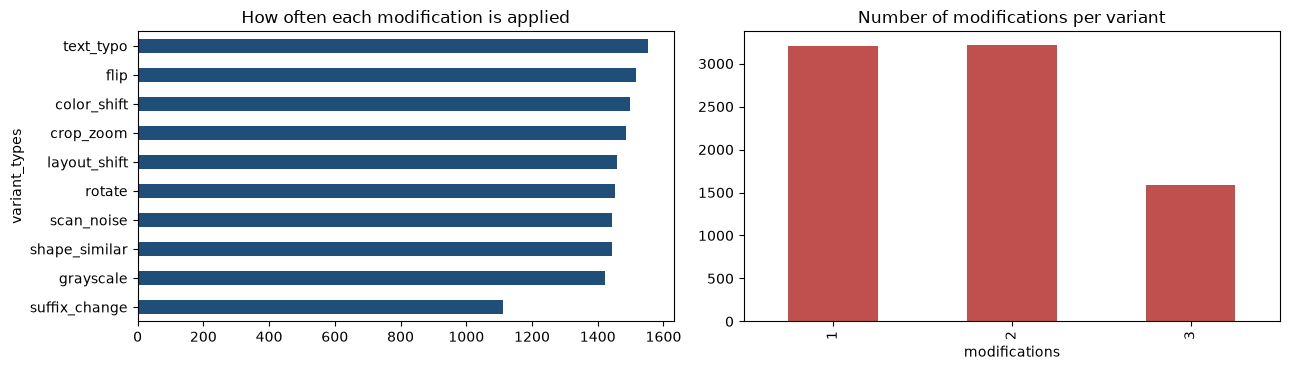

In [7]:
variants = df[df.is_parent == 0].copy()
variants["n_transforms"] = variants["variant_types"].str.count(r"\+") + 1
transform_counts = variants["variant_types"].str.split("+").explode().value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
transform_counts.plot.barh(ax=axes[0], color="#1f4e79")
axes[0].invert_yaxis()
axes[0].set_title("How often each modification is applied")
variants["n_transforms"].value_counts().sort_index().plot.bar(ax=axes[1], color="#c0504d")
axes[1].set_title("Number of modifications per variant")
axes[1].set_xlabel("modifications")
plt.tight_layout()
plt.savefig(ASSETS / "variant_stats.png", dpi=110, bbox_inches="tight")
plt.show()

| Modification | What it simulates |
|---|---|
| `color_shift` | Same mark in a different colour scheme |
| `text_typo` | One letter changed / swapped / removed ("Nusantara" -> "Nusantra") |
| `suffix_change` | Same core name, different descriptor ("Siwi Group" -> "Siwi Kopi") |
| `shape_similar` | Device element replaced by a similar shape |
| `layout_shift` | Elements resized or moved |
| `rotate`, `flip` | Orientation changes |
| `scan_noise` | Low-quality scan / heavy JPEG compression |
| `crop_zoom` | Partially cropped logo |
| `grayscale` | Black-and-white publication |

## 5. Example logo families
First column = parent logo, the rest = its variants (titles show the modifications).

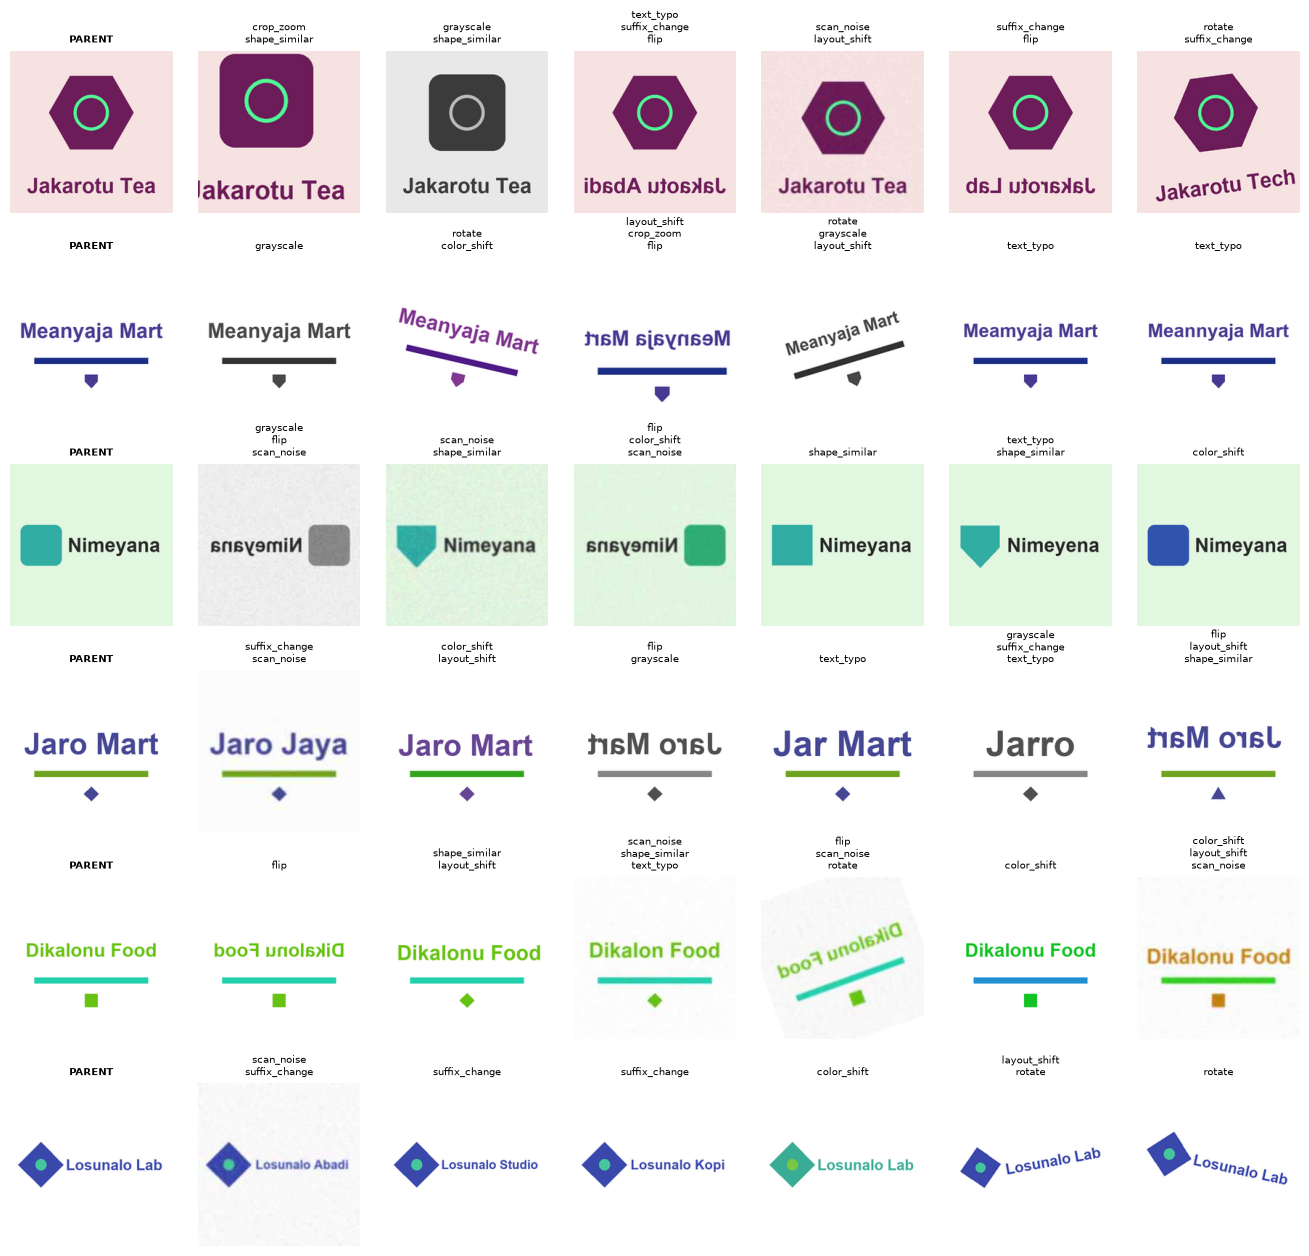

In [8]:
rng = np.random.default_rng(SEED)
sample_ids = rng.choice(df.parent_id.unique(), 6, replace=False)
show_families(df, IMAGE_DIR, sample_ids, n_cols=7, save_path=ASSETS / "sample_families.png")

## Summary
* 9,000 images, 1,000 distinct marks, split 70 / 15 / 15 by mark.
* Every variant keeps a `parent_id` label, which defines what "similar" means for evaluation.
* Next notebook: a zero-training baseline using pretrained CLIP embeddings + FAISS.